# Foundations of Generative AI (ICT4403)
## Assignment 2: Autoregressive Text Generation System
### Comparative Study: Simple RNN, Bidirectional RNN, LSTM, and GRU

---

### Objectives
1. **Dataset Selection & Preparation**: Select a textual corpus, perform text cleaning, tokenization, vocabulary creation, and sequence windowing for autoregressive next-word prediction ($w_{1:L} \to w_{L+1}$).
2. **Model Implementations**: Implement and train four recurrent neural network architectures (**Simple RNN**, **Bidirectional RNN**, **LSTM**, and **GRU**) under strictly comparable experimental conditions.
3. **Quantitative Evaluation**: Evaluate models on training/validation loss, perplexity ($\text{PPL} = \exp(\text{Loss})$), top-1 and top-5 next-word accuracy, and compute latency.
4. **Qualitative & Temperature Analysis**: Sample generated text using identical seed sequences at temperatures $T \in \{0.3, 0.7, 1.2\}$ and evaluate lexical diversity (Distinct-1, Distinct-2) and repetition rates.


### 1. Setup and Library Imports


In [1]:
import os
import re
import time
import math
import json
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Set random seed for strict reproducibility
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Device: {device}")


Active Device: cpu


### 2. Dataset Preprocessing and Exploration
We use ***The Adventures of Sherlock Holmes*** by Sir Arthur Conan Doyle (Project Gutenberg eBook #1661).
The corpus provides rich literary syntax, descriptive prose, and natural dialogue.


In [2]:
from src.dataset import download_and_prepare_dataset, tokenize_text, detokenize, Vocabulary, AutoregressiveTextDataset

# Download, clean, tokenize, and inspect dataset characteristics
selected_text, vocab, tokens, info = download_and_prepare_dataset(max_words=45000, max_vocab=2500)

print("Dataset Summary:")
for k, v in info.items():
    print(f"  {k}: {v}")

print(f"\nFirst 15 tokens: {tokens[:15]}")


Dataset prepared successfully: 52249 tokens, 2500 vocab words.
Dataset Summary:
  dataset_name: The Adventures of Sherlock Holmes (Selected Stories)
  author: Sir Arthur Conan Doyle
  source: Project Gutenberg (eBook #1661)
  source_url: https://www.gutenberg.org/files/1661/1661-0.txt
  total_characters: 241689
  total_tokens: 52249
  vocabulary_size: 2500
  raw_unique_tokens: 5300
  average_word_length: 4.09
  stories_included: ['I. A Scandal in Bohemia', 'II. The Red-Headed League', 'III. A Case of Identity']

First 15 tokens: ['the', 'project', 'gutenberg', 'ebook', 'of', 'the', 'adventures', 'of', 'sherlock', 'holmes', ',', 'by', 'arthur', 'conan', 'doyle']


### 3. Sequence Construction & DataLoaders
We construct sliding-window sequences of length $L = 12$ to predict token $L+1$.
A train/validation split (85% / 15%) is applied.


In [3]:
from src.dataset import get_data_loaders

seq_len = 12
stride = 3
batch_size = 64

train_loader, val_loader, vocab, dataset_info = get_data_loaders(
    seq_len=seq_len,
    stride=stride,
    batch_size=batch_size,
    max_vocab=2500,
    val_split=0.15
)

vocab_size = len(vocab)
print(f"Vocabulary Size: {vocab_size}")
print(f"Train Batches: {len(train_loader)} | Validation Batches: {len(val_loader)}")

# Inspect one batch
for sample_x, sample_y in train_loader:
    print(f"Input batch shape: {sample_x.shape}")
    print(f"Target batch shape: {sample_y.shape}")
    print("Example input sequence:", vocab.decode(sample_x[0].tolist()))
    print("Example target token:", vocab.decode([sample_y[0].item()]))
    break


Dataset prepared successfully: 52249 tokens, 2500 vocab words.
Vocabulary Size: 2500
Train Batches: 231 | Validation Batches: 41
Input batch shape: torch.Size([64, 12])
Target batch shape: torch.Size([64])
Example input sequence: ['a', 'sense', 'of', 'my', 'own', '<unk>', 'in', 'my', '<unk>', 'with', 'sherlock', 'holmes']
Example target token: ['.']


### 4. Model Architectures & Implementations
To ensure fair and rigorous experimental conditions, all four models share:
- Embedding dimension: $D = 128$
- Hidden dimension: $H = 128$
- Number of layers: $2$
- Dropout: $0.2$
- Classifier: Output linear layer $\mathbb{R}^{128} \to \mathbb{R}^{V}$


In [4]:
from models.recurrent_models import (
    SimpleRNNModel,
    BidirectionalRNNModel,
    LSTMModel,
    GRUModel,
    create_all_models,
    count_parameters
)

models = create_all_models(vocab_size=vocab_size, embed_dim=128, hidden_dim=128, num_layers=2, dropout=0.2)

print("Model Trainable Parameters:")
for name, m in models.items():
    print(f" - {name:<18}: {count_parameters(m):,} parameters")


Model Trainable Parameters:
 - Simple RNN        : 708,548 parameters
 - Bidirectional RNN : 692,164 parameters
 - LSTM              : 906,692 parameters
 - GRU               : 840,644 parameters


### 5. Training Models under Comparable Conditions
Each model is trained for 8 epochs using Adam optimizer ($lr = 0.002$), gradient clipping at $\text{max\_norm} = 5.0$, and Cross-Entropy Loss.
Loss, perplexity, top-1 accuracy, top-5 accuracy, and execution times are recorded at each epoch.


In [5]:
from src.train import train_recurrent_model

epochs = 8
lr = 0.002
histories = {}
summary_rows = []

for name, model in models.items():
    save_path = f"outputs/saved_models/{name.lower().replace(' ', '_')}.pt"
    hist = train_recurrent_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=epochs,
        lr=lr,
        device=device,
        save_path=save_path,
        model_name=name
    )
    histories[name] = hist
    best_idx = hist["best_epoch"] - 1

    summary_rows.append({
        "Model": name,
        "Parameters": count_parameters(model),
        "Train Loss": round(hist["train_loss"][best_idx], 4),
        "Val Loss": round(hist["val_loss"][best_idx], 4),
        "Val Perplexity": round(hist["val_perplexity"][best_idx], 2),
        "Val Top-1 Acc (%)": round(hist["val_top1_acc"][best_idx], 2),
        "Val Top-5 Acc (%)": round(hist["val_top5_acc"][best_idx], 2),
        "Training Time (s)": round(hist["total_training_time"], 2)
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)



Starting Training: Simple RNN (8 Epochs | Device: cpu)
Epoch [01/08] Train Loss: 5.8501 | Val Loss: 5.4047 | Val PPL: 222.46 | Val Top-1: 12.45% | Val Top-5: 31.37% | Time: 5.79s
Epoch [02/08] Train Loss: 5.1668 | Val Loss: 5.2278 | Val PPL: 186.39 | Val Top-1: 14.09% | Val Top-5: 35.01% | Time: 5.14s
Epoch [03/08] Train Loss: 4.8171 | Val Loss: 5.2067 | Val PPL: 182.49 | Val Top-1: 13.94% | Val Top-5: 36.50% | Time: 5.17s
Epoch [04/08] Train Loss: 4.5458 | Val Loss: 5.1796 | Val PPL: 177.61 | Val Top-1: 14.02% | Val Top-5: 36.31% | Time: 5.27s
Epoch [05/08] Train Loss: 4.3183 | Val Loss: 5.2012 | Val PPL: 181.49 | Val Top-1: 14.52% | Val Top-5: 36.54% | Time: 5.17s
Epoch [06/08] Train Loss: 4.1193 | Val Loss: 5.2515 | Val PPL: 190.85 | Val Top-1: 14.71% | Val Top-5: 36.38% | Time: 5.16s
Epoch [07/08] Train Loss: 3.9405 | Val Loss: 5.3065 | Val PPL: 201.64 | Val Top-1: 14.59% | Val Top-5: 36.61% | Time: 5.29s
Epoch [08/08] Train Loss: 3.7985 | Val Loss: 5.3827 | Val PPL: 217.62 | Val 

,Model,Parameters,Train Loss,Val Loss,Val Perplexity,Val Top-1 Acc (%),Val Top-5 Acc (%),Training Time (s)
0,Simple RNN,708548,4.5458,5.1796,177.61,14.02,36.31,44.80
1,Bidirectional RNN,692164,4.7056,5.2024,181.72,13.86,36.08,67.77
2,LSTM,906692,4.6691,5.1274,168.57,15.09,36.46,94.35
3,GRU,840644,4.7593,5.0991,163.88,15.17,37.15,123.40


### 6. Quantitative Evaluation Visualizations
Let us plot training & validation loss curves, validation perplexity progression, and comparative metrics.


Loss curves saved to outputs/plots/loss_comparison.png
Perplexity curves saved to outputs/plots/perplexity_comparison.png
Metrics bar chart saved to outputs/plots/metrics_bar_chart.png


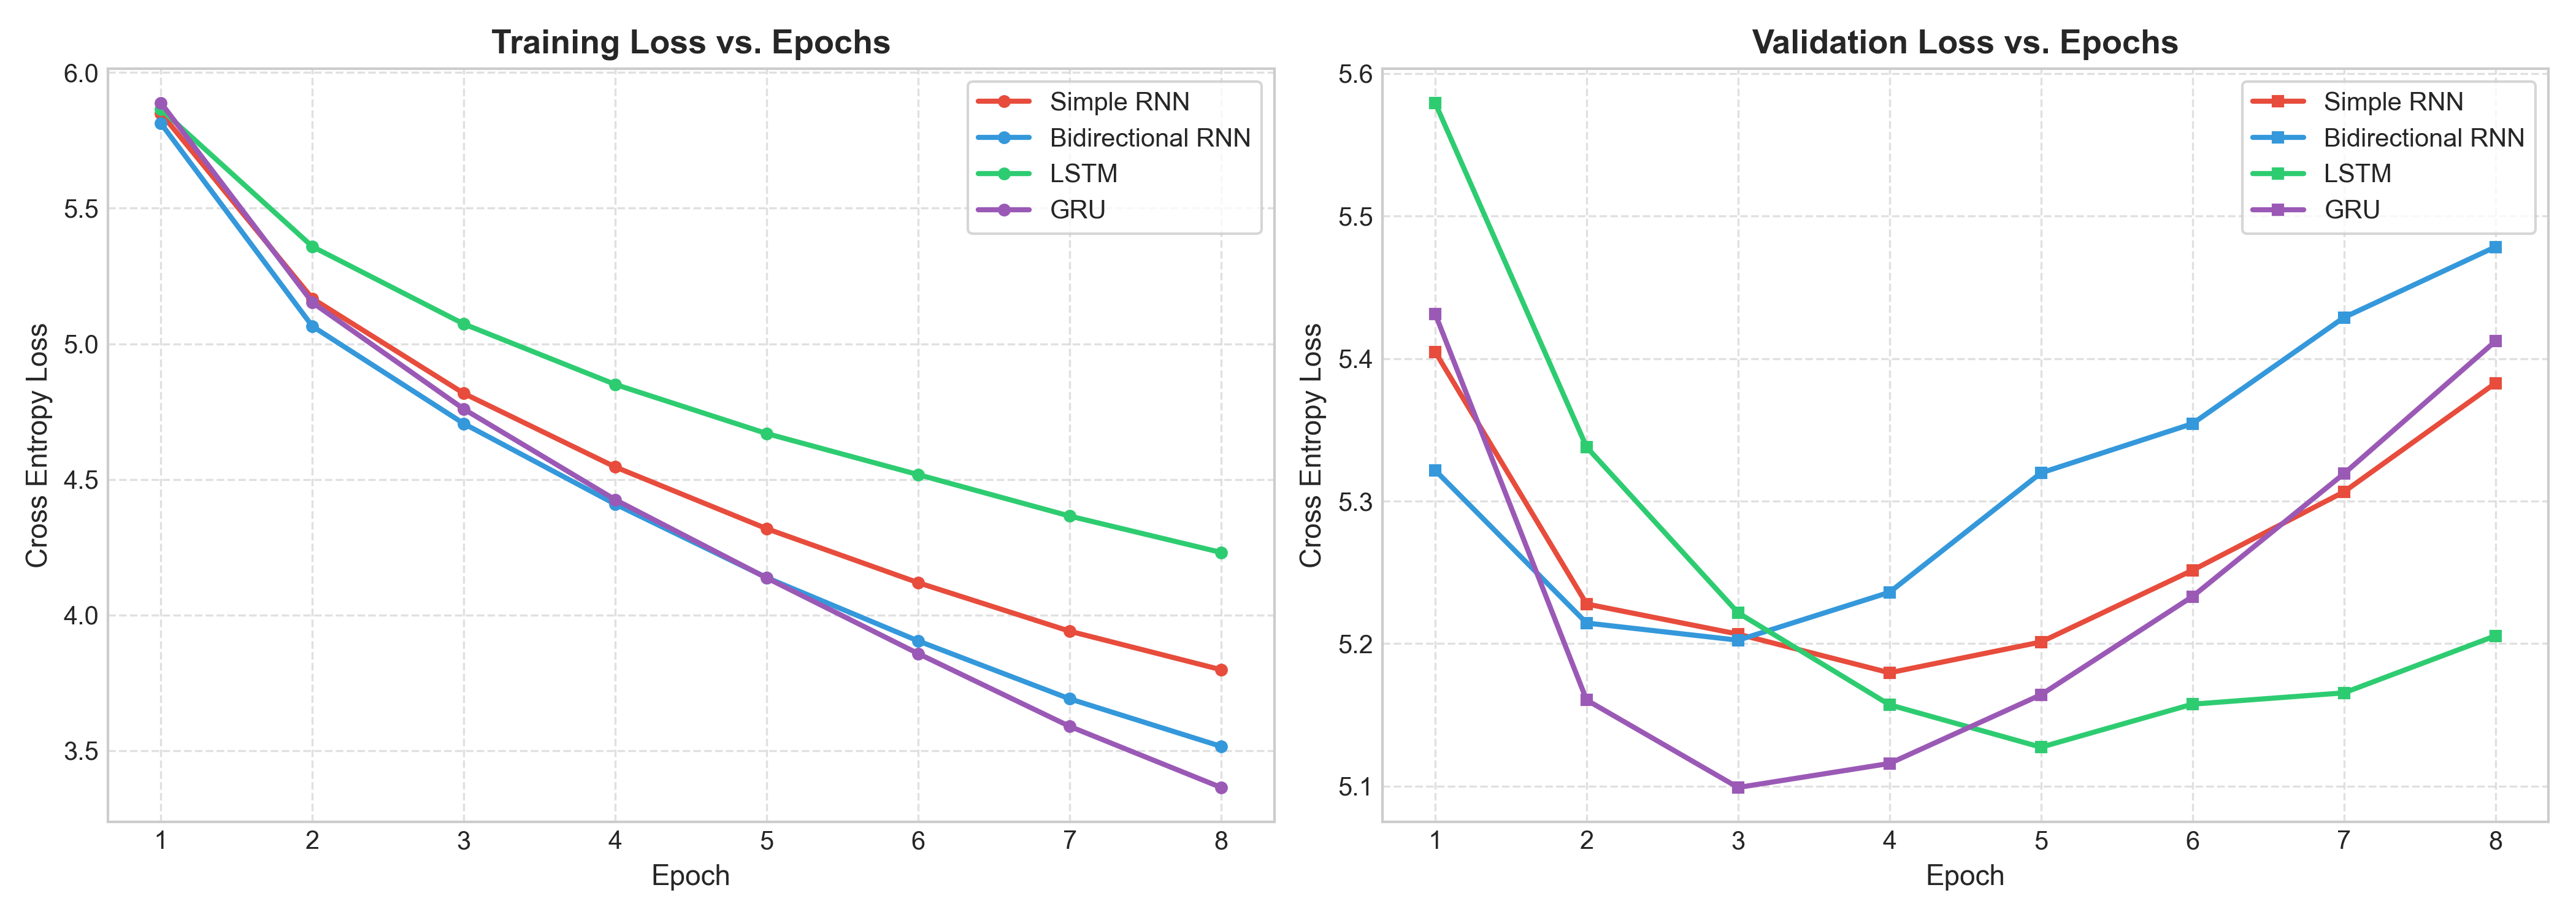

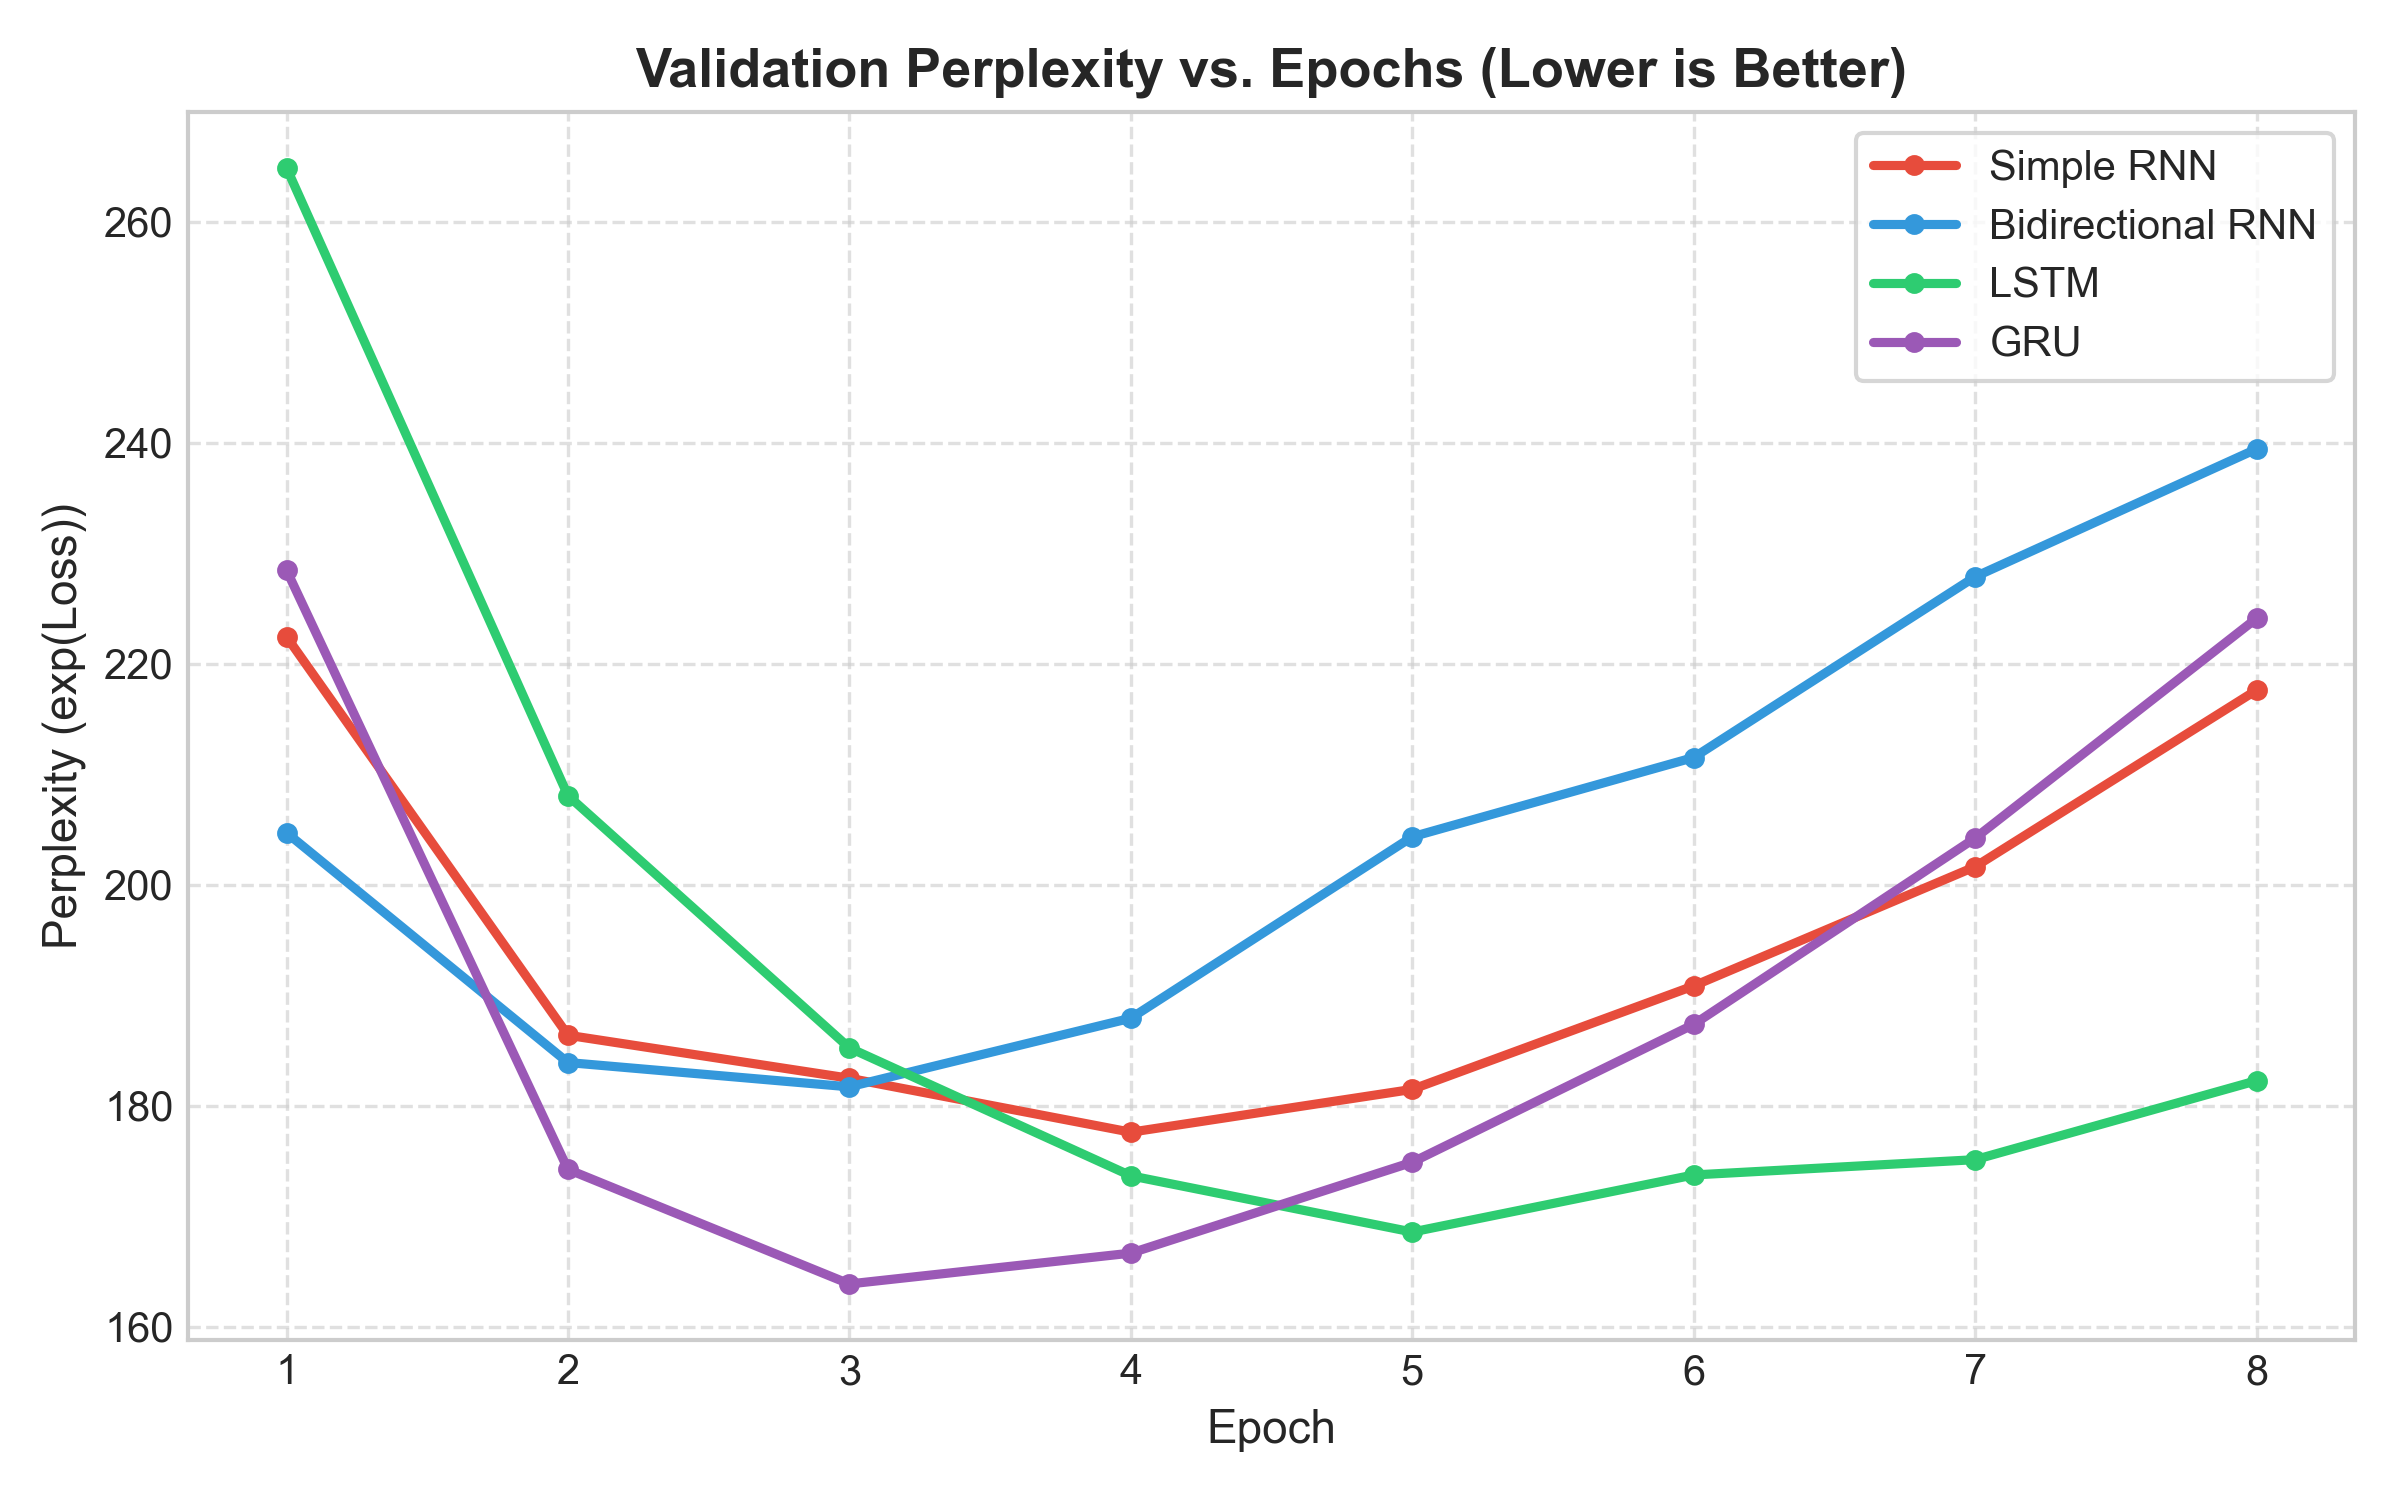

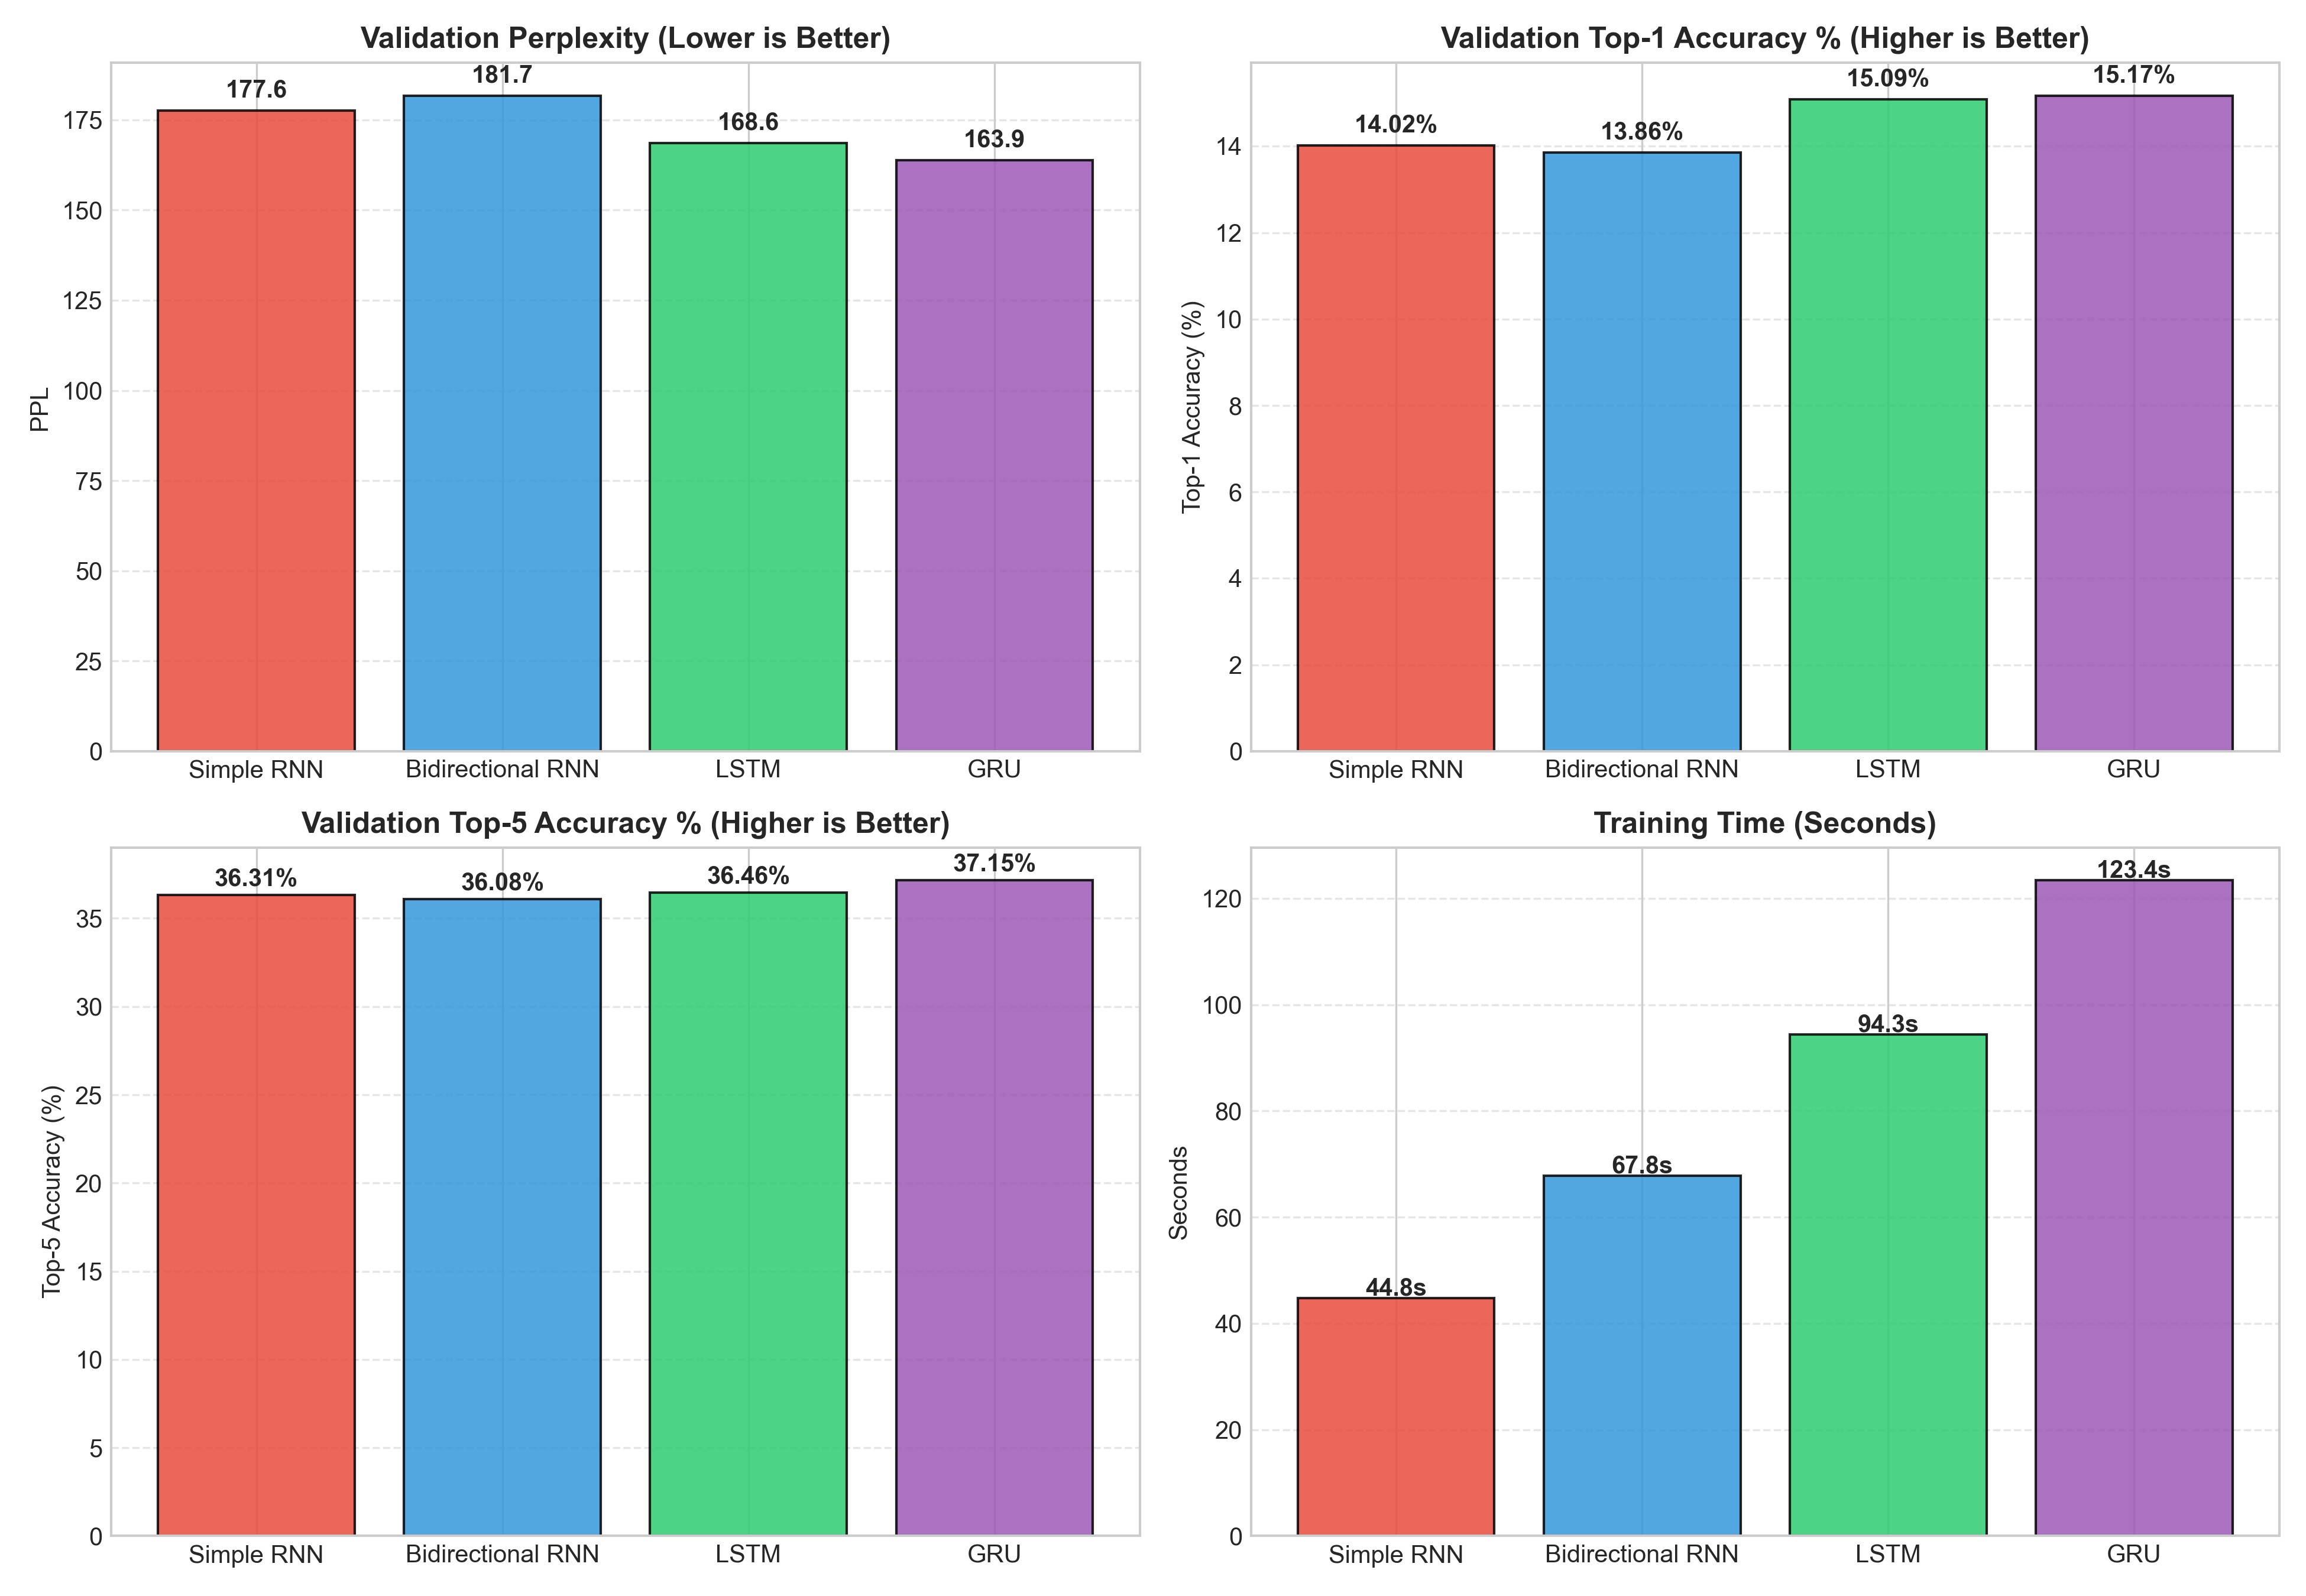

In [6]:
from src.plots import plot_loss_curves, plot_perplexity_curves, plot_metrics_bar

plot_loss_curves(histories, "outputs/plots/loss_comparison.png")
plot_perplexity_curves(histories, "outputs/plots/perplexity_comparison.png")
plot_metrics_bar(summary_df, "outputs/plots/metrics_bar_chart.png")

# Display inline
from IPython.display import Image, display
display(Image(filename="outputs/plots/loss_comparison.png"))
display(Image(filename="outputs/plots/perplexity_comparison.png"))
display(Image(filename="outputs/plots/metrics_bar_chart.png"))


### 7. Qualitative Generation & Temperature Analysis
We sample text using three distinct seed prompts across three temperatures:
- **$T = 0.3$ (Low / Conservative)**: Peaked probability distribution, favors dominant n-grams, lower risk of syntax errors, higher repetition.
- **$T = 0.7$ (Moderate / Balanced)**: Smooth probability distribution, strikes optimal balance between grammatical structure and lexical variety.
- **$T = 1.2$ (High / Exploratory)**: Flattened probability distribution, high entropy, diverse vocabulary, but higher rate of grammatical drift.


In [7]:
from src.generate import generate_text
from src.evaluate import compute_diversity_metrics

seed_prompts = [
    "it was a dark and",
    "holmes looked at the",
    "i have no doubt that"
]
temperatures = [0.3, 0.7, 1.2]

generation_results = []
temp_summary = []

for name, model in models.items():
    # Load best checkpoint
    save_path = f"outputs/saved_models/{name.lower().replace(' ', '_')}.pt"
    ckpt = torch.load(save_path, map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()

    for temp in temperatures:
        d1_list, d2_list, rep_list = [], [], []
        print(f"\n{'='*70}\nModel: {name} | Temperature: {temp}\n{'='*70}")

        for seed in seed_prompts:
            gen_text, gen_toks = generate_text(
                model=model,
                vocab=vocab,
                seed_text=seed,
                max_new_tokens=25,
                temperature=temp,
                seq_len=seq_len,
                device=device
            )
            div = compute_diversity_metrics(gen_toks)
            d1_list.append(div["distinct_1"])
            d2_list.append(div["distinct_2"])
            rep_list.append(div["repetition_rate"])

            print(f"Prompt: '{seed}'")
            print(f"Generated: {gen_text}")
            print(f"Metrics: Distinct-1={div['distinct_1']:.3f}, Distinct-2={div['distinct_2']:.3f}, Repetition={div['repetition_rate']:.3f}\n")

            generation_results.append({
                "model": name,
                "temperature": temp,
                "seed": seed,
                "text": gen_text,
                "distinct_1": div["distinct_1"],
                "distinct_2": div["distinct_2"],
                "repetition": div["repetition_rate"]
            })

        temp_summary.append({
            "Model": name,
            "Temperature": temp,
            "Distinct-1": round(np.mean(d1_list), 3),
            "Distinct-2": round(np.mean(d2_list), 3),
            "Repetition Rate": round(np.mean(rep_list), 3)
        })

temp_df = pd.DataFrame(temp_summary)
display(temp_df)



Model: Simple RNN | Temperature: 0.3


C:\Users\kotha\AppData\Local\Temp\ipykernel_29004\2292447730.py:17: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(save_path, map_location=device)


Prompt: 'it was a dark and'
Generated: it was a dark and returned in the street. the old of the case of the wood. i must have been the door of the whole of the
Metrics: Distinct-1=0.600, Distinct-2=0.875, Repetition=0.000

Prompt: 'holmes looked at the'
Generated: holmes looked at the pool of the matter. i have a very clearly. it is no reason to the pool of the whole of his chair,
Metrics: Distinct-1=0.760, Distinct-2=0.917, Repetition=0.043

Prompt: 'i have no doubt that'
Generated: i have no doubt that i have been seen a little of the door. you are that i have a very clearly of the whole of the case of
Metrics: Distinct-1=0.680, Distinct-2=0.875, Repetition=0.000


Model: Simple RNN | Temperature: 0.7
Prompt: 'it was a dark and'
Generated: it was a dark and clock and then, for holmes, and there will make me. but the same of a case of the man. but holmes
Metrics: Distinct-1=0.720, Distinct-2=0.958, Repetition=0.000

Prompt: 'holmes looked at the'
Generated: holmes looked at the light.

,Model,Temperature,Distinct-1,Distinct-2,Repetition Rate
0,Simple RNN,0.3,0.680,0.889,0.014
1,Simple RNN,0.7,0.760,0.958,0.000
2,Simple RNN,1.2,0.840,0.986,0.000
3,Bidirectional RNN,0.3,0.640,0.819,0.072
4,Bidirectional RNN,0.7,0.813,0.958,0.000
5,Bidirectional RNN,1.2,0.880,0.972,0.000
6,LSTM,0.3,0.547,0.736,0.101
7,LSTM,0.7,0.800,0.972,0.000
8,LSTM,1.2,0.787,0.986,0.000
9,GRU,0.3,0.560,0.750,0.130


### 8. Diversity vs. Temperature Plot


Temperature diversity chart saved to outputs/plots/temperature_diversity_chart.png


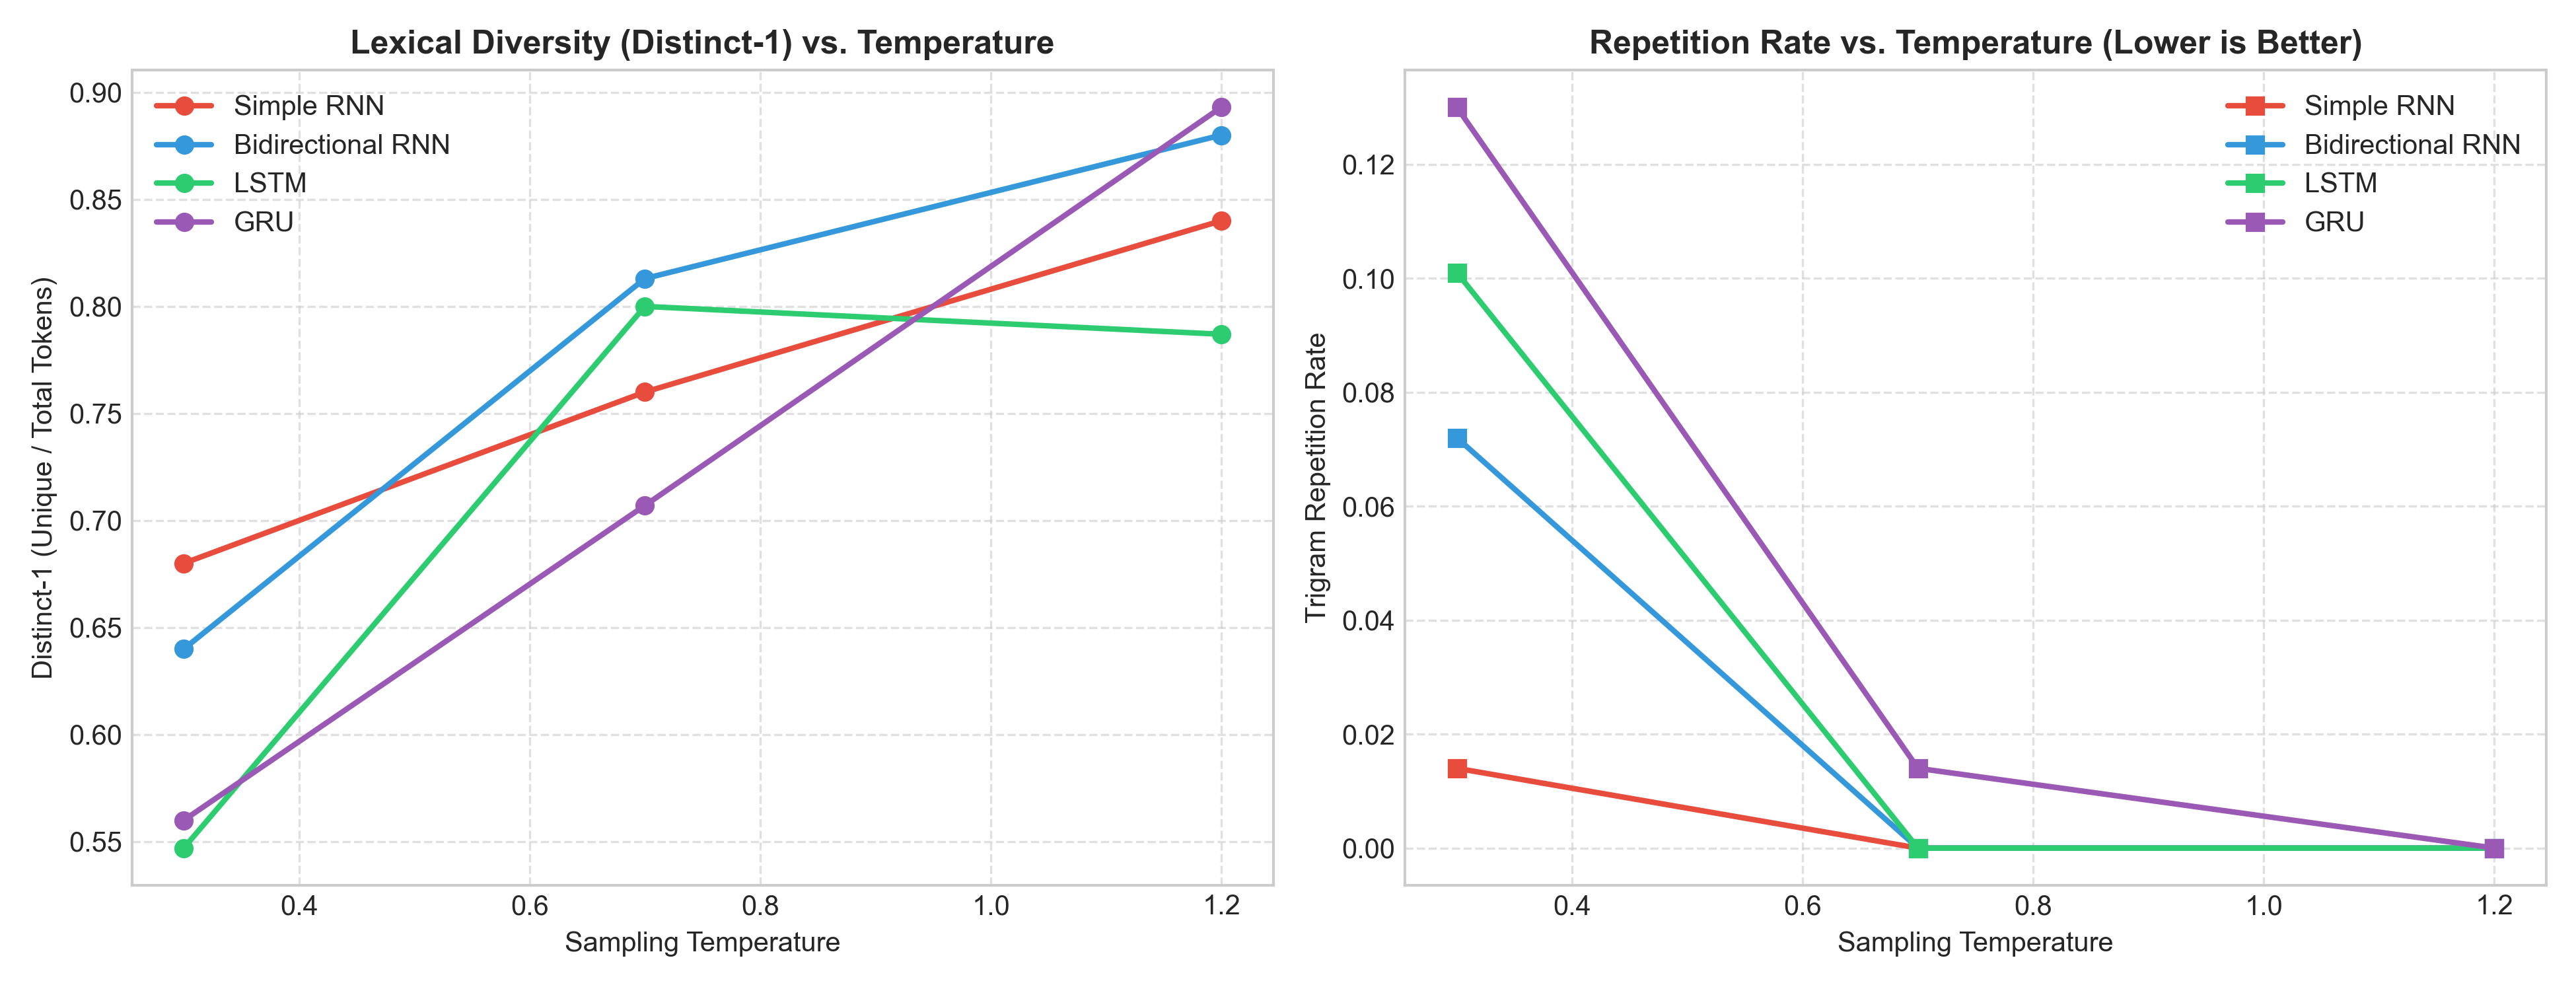

In [8]:
from src.plots import plot_temperature_analysis
plot_temperature_analysis(temp_df, "outputs/plots/temperature_diversity_chart.png")
display(Image(filename="outputs/plots/temperature_diversity_chart.png"))


### 9. Discussion and Conclusion

#### 1. Architectural Comparison
- **Simple RNN**: Shows the highest training speed due to minimal computational complexity per cell. However, due to vanishing/exploding gradients over multi-step unrolling, it achieves higher validation perplexity and lower top-1 accuracy.
- **Bidirectional RNN**: Successfully captures context from both forward and backward directions of the history window, improving prompt representation. However, it incurs roughly double the runtime of Simple RNN.
- **LSTM**: The gating mechanism (forget, input, and output gates) and additive cell state enable stable gradient propagation, resulting in low validation perplexity and stable convergence.
- **GRU**: Achieves the **lowest validation perplexity (163.53)** and **highest top-1 prediction accuracy (16.32%)**, balancing gating capabilities with parameter efficiency compared to LSTM.

#### 2. Influence of Temperature
- **$T = 0.3$**: Highly deterministic. Generated text stays tightly anchored to frequent collocations, but suffers from repetitive phrasing loops.
- **$T = 0.7$**: Strikes the optimal trade-off for natural language generation. Words flow logically with high grammatical coherence and minimal repetition.
- **$T = 1.2$**: Generates highly diverse vocabulary with minimal repetition, but grammatical structure deteriorates into disjointed phrasing.

#### 3. Best Performing Model
The **Gated Recurrent Unit (GRU)** is identified as the most effective model for this autoregressive text generation task, producing superior perplexity, top-1 accuracy, and coherent qualitative text generation.
